# 10. 일기 감정 분석 — 문맥 검증 + 사용자 화면

> 09와 분석 로직은 같고, 맨 아래 사용자 화면(셀 22~25)의 하루 카드를 단순화한 버전 (세부 감정은 이름만, 문장별 감정·★ 표시 제거)

**작성자: 김민서**  
**작성일: 2026-11-23**

## 09에서 수정한 내용 (08-v2 대비, 11/23 박상현)

1. **'~서' 원인절 뒤 작성자 감정을 타인 감정으로 오판하던 문제 수정**
   - 08-v2는 원인절 경계가 `해서·아서·어서·줘서` 등 일부 형태뿐이라 `아파서·주셔서·다쳐서`에서 절이 안 끊겼음
   - 그래서 `동생이 아파서 걱정됐다`, `선생님이 칭찬해 주셔서 기뻤다`, `엄마가 아프셔서 슬펐다`의 감정을 타인 감정으로 보고 확률을 0으로 만들었음
   - '서'로 끝나는 어절 전체를 원인절 경계로 처리 (단, 장소 조사 '에서'는 제외) → 테스트 7건 추가
2. **`INCLUDE_VALID_MENTION_BELOW_THRESHOLD = False`**
   - 감정 단어가 있어도 모델이 그 감정을 선택(확률 ≥ 감정별 임계값)했을 때만 결과에 넣고 맨 앞에 표시
   - `영화가 기대 이하였다`→기대감, `감사 인사를 드렸다`→고마움, `행복주택 발표`→행복처럼 다른 뜻의 단어가 강제로 들어가는 것 방지

3. **사용자 화면 추가** (맨 아래 셀 22~25)
   - `show_day()`: 하루 결과 카드 (대표 감정, 긍정·부정 막대, 세부 감정 Top5, 코멘트)
   - `show_month()`: 한 달 요약 카드 (대표 감정 분포, 자주 나온 세부 감정, 가장 좋았던/힘들었던 날) + 캘린더·그래프
   - 분석 로직은 그대로, 표시만 사용자용으로 정리. 카드는 `outputs/card_*.html`로 저장 가능 (발표 캡처용)

## 07 대비 핵심 개선 (08-v2, 김민서)

1. **`혼합` 대표 감정 제거**
   - 대표 감정은 **행복 / 기대 / 슬픔 / 분노 / 불안 / 피로 / 중립** 중 하나로 유지합니다.
   - 여러 감정은 문장별 결과와 세부 감정 Top 5에서 함께 보여줍니다.

2. **직접 언급 감정의 문맥 검사**
   - 부정, 가정·희망·예상, 타인 감정, 인용·전달, 명시적 과거 회상을 검사합니다.
   - 감정 단어가 있다는 이유만으로 현재 작성자의 감정으로 확정하지 않습니다.

3. **문맥상 제외된 감정을 최종 판정에도 제한적으로 반영**
   - 제외된 **해당 세부 감정 라벨의 확률만** 문맥 보정값으로 낮춥니다.
   - 보정된 확률을 대표 감정, 긍정·부정 점수, 사용자용 Top 5 계산에 사용합니다.
   - 문장 전체나 같은 그룹 전체를 지우지는 않아 KoBERT의 다른 문맥 판단은 유지합니다.
   - 보정 전 대표 감정과 보정 후 대표 감정을 함께 저장하여 결과를 추적할 수 있습니다.

## 이번 v2에서 추가 수정한 내용

1. **실제 오판 3건 수정 및 회귀 테스트 추가**
   - `교수님이 ... 너무 민망했다.` → 작성자의 **부끄러움** 인정
   - `친구가 밥을 사 줘서 정말 고마웠다.` → 작성자의 **고마움** 인정
   - `주문을 잘못 받아서 ... 미안했다.` → **죄책감** 인정

2. **`잘못` 내부의 `못` 오인 방지**
   - `안`, `못`은 독립된 어절일 때만 앞 부정어로 처리합니다.

3. **원인절의 행동 주체와 뒤 감정절의 경험자 분리**
   - `~해서`, `~줘서`, `~가서`, `덕분에`, `때문에`, `뒤에` 등의 절 경계를 기준으로 가장 가까운 감정절의 주체를 검사합니다.

4. **문맥상 제외된 감정을 사용자용 Top 5에서 제거**
   - `하나도 안 지루했다`에서 `재미없음`이 다시 노출되는 모순을 방지합니다.

5. **대표 감정의 우세 정도 표시**
   - 대표 감정 강도, 2순위 감정, 두 그룹의 점수 차이, 긍정·부정 차이와 우세도를 함께 출력합니다.

6. **모델 해시 기반 calibration 캐시**
   - 같은 파일명이라도 모델 내용이 다르면 별도 캐시를 사용하도록 SHA256 앞 12자리를 캐시 이름에 포함합니다.

## 유지한 부분

- 모델은 `kobert_kote_nall_e5.pt`를 사용하며 재학습하지 않습니다.
- 44개 KOTE 감정, 감정별 임계값 보정, 예측 캐시, 문장 분리, 긍정·부정 그래프, 감정 캘린더 구조를 유지합니다.



In [37]:
# 1. 기본 설정
import re
import calendar
import hashlib
from pathlib import Path
from datetime import date
from IPython.display import display

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Rectangle, Patch


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
model_dir = project_root / "models"
data_dir = project_root / "data"
output_dir = project_root / "outputs"
output_dir.mkdir(exist_ok=True)

for font_name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if any(font_name == item.name for item in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font_name
        break

plt.rcParams["axes.unicode_minus"] = False

print("project_root:", project_root)
print("font:", plt.rcParams["font.family"])


device: cuda
project_root: e:\박상현 학교\2학년2학기\기계학습\10조_미니프로젝트#1_기계학습[00]\diary_emotion_project
font: ['Malgun Gothic']


In [38]:
# 2. 설정
MODEL_FILE = "kobert_kote_nall_e5.pt"
DIARY_FILE = data_dir / "sample_diary.csv"
CONTEXT_RULE_VERSION = "09"

THRESHOLD = None
SPLIT_CONNECTIVES = True
GROUP_TOP_K = 2
NEUTRAL_MIN_SCORE = 0.35

# 긍정/부정 그룹 수가 달라도 같은 기준으로 비교
POLARITY_AGG = "max"  # "mean" 또는 "max"

# 07에서 유지한 감정별 임계값 보정
USE_CLASS_THRESHOLD = True
CLASS_TH_GRID = [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80]
CLASS_TH_MIN_POS = 30
RANK_BY_BASELINE = False

# 문맥 검증형 직접 감정 처리
USE_CONTEXT_MENTION = True
PRIORITIZE_CONTEXT_MENTION = True
# 09: False → 감정 단어가 있어도 모델 확률이 그 감정의 임계값을 넘을 때만 선택 (선택된 경우 맨 앞에 표시)
#     True면 '기대 이하였다'→기대감, '감사 인사'→고마움, '행복주택'→행복처럼 다른 뜻의 단어도 강제로 선택됨
INCLUDE_VALID_MENTION_BELOW_THRESHOLD = False
CONTEXT_WINDOW = 48

# 문맥상 제외된 '해당 세부 감정 라벨'만 최종 점수 계산에서 낮춘다.
# 전체 감정 그룹을 삭제하지 않으므로 모델의 다른 문맥 추론은 유지된다.
APPLY_CONTEXT_EXCLUSION_TO_MODEL = True
CONTEXT_EXCLUDED_PROB_CAP = 0.0

# 대표 감정과 2순위 감정의 강도 차이에 따른 우세도 기준
DOMINANCE_GAP_VERY_LOW = 0.03
DOMINANCE_GAP_LOW = 0.08
DOMINANCE_GAP_MEDIUM = 0.15

# 08에서는 혼합 대표 감정을 사용하지 않음
DISPLAY_EMOTIONS = ["행복", "기대", "슬픔", "분노", "불안", "피로", "중립"]


In [39]:
# 3. KOTE 44개 세부 감정 + 7개 대표 감정 그룹
LABELS = [
    '불평/불만','환영/호의','감동/감탄','지긋지긋','고마움','슬픔','화남/분노','존경',
    '기대감','우쭐댐/무시함','안타까움/실망','비장함','의심/불신','뿌듯함','편안/쾌적',
    '신기함/관심','아껴주는','부끄러움','공포/무서움','절망','한심함','역겨움/징그러움',
    '짜증','어이없음','없음','패배/자기혐오','귀찮음','힘듦/지침','즐거움/신남','깨달음',
    '죄책감','증오/혐오','흐뭇함(귀여움/예쁨)','당황/난처','경악','부담/안 내킴','서러움',
    '재미없음','불쌍함/연민','놀람','행복','불안/걱정','기쁨','안심/신뢰'
]

GROUPS = {
    "기쁨·만족": [
        '환영/호의','감동/감탄','고마움','존경','뿌듯함','편안/쾌적','아껴주는',
        '흐뭇함(귀여움/예쁨)','행복','기쁨','즐거움/신남','안심/신뢰'
    ],
    "기대·관심": ['기대감','신기함/관심','깨달음','비장함'],
    "슬픔·실망": [
        '슬픔','안타까움/실망','절망','서러움','불쌍함/연민',
        '패배/자기혐오','죄책감','부끄러움'
    ],
    "분노·불만": [
        '불평/불만','화남/분노','짜증','어이없음','한심함',
        '역겨움/징그러움','증오/혐오','의심/불신','우쭐댐/무시함'
    ],
    "불안·당황": ['공포/무서움','불안/걱정','당황/난처','경악','놀람','부담/안 내킴'],
    "피로·지루함": ['지긋지긋','귀찮음','힘듦/지침','재미없음'],
    "없음": ['없음']
}

DISPLAY_EMOTION = {
    "기쁨·만족": "행복",
    "기대·관심": "기대",
    "슬픔·실망": "슬픔",
    "분노·불만": "분노",
    "불안·당황": "불안",
    "피로·지루함": "피로",
    "없음": "중립"
}

POSITIVE_GROUPS = ["기쁨·만족", "기대·관심"]
NEGATIVE_GROUPS = ["슬픔·실망", "분노·불만", "불안·당황", "피로·지루함"]
NON_NEUTRAL_GROUPS = POSITIVE_GROUPS + NEGATIVE_GROUPS
GROUP_NAMES = list(GROUPS)
GROUP_IDX = {group: [LABELS.index(emotion) for emotion in emotions]
             for group, emotions in GROUPS.items()}
LABEL_GROUP = {idx: group for group, indices in GROUP_IDX.items() for idx in indices}

EMOTION_COLORS = {
    "행복": "#F2C94C",
    "기대": "#5DBB8F",
    "슬픔": "#5B8DEF",
    "분노": "#E5534B",
    "불안": "#9B6FD3",
    "피로": "#8D7B68",
    "중립": "#BDBDBD"
}

all_idx = sum(GROUP_IDX.values(), [])
assert sorted(all_idx) == list(range(44)), "44개 감정 매핑을 확인하세요."
assert set(DISPLAY_EMOTIONS) == set(EMOTION_COLORS), "대표 감정과 색상 매핑을 확인하세요."

print("Positive:", POSITIVE_GROUPS)
print("Negative:", NEGATIVE_GROUPS)
print("Display:", DISPLAY_EMOTIONS)


Positive: ['기쁨·만족', '기대·관심']
Negative: ['슬픔·실망', '분노·불만', '불안·당황', '피로·지루함']
Display: ['행복', '기대', '슬픔', '분노', '불안', '피로', '중립']


In [40]:
# 4. 최종 KoBERT 모델 불러오기 + 모델 해시 확인
from kobert_tokenizer import KoBERTTokenizer
from transformers import BertModel

MODEL_NAME = "skt/kobert-base-v1"
tokenizer = KoBERTTokenizer.from_pretrained(MODEL_NAME)

assert tokenizer.encode("한국어 모델을 공유합니다.") == [
    2, 4958, 6855, 2046, 7088, 1050, 7843, 54, 3
], "KoBERT 토크나이저가 정상적으로 로드되지 않았습니다."


class KoBERTMultiLabelClassifier(nn.Module):
    def __init__(self, num_labels=44, dropout=0.2):
        super().__init__()
        self.bert = BertModel.from_pretrained(MODEL_NAME)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(self.bert.config.hidden_size, num_labels)

    def forward(self, input_ids, attention_mask=None, token_type_ids=None):
        out = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )
        cls_vector = out.last_hidden_state[:, 0, :]
        return self.classifier(self.dropout(cls_vector))


def file_sha256(path, chunk_size=1024 * 1024):
    """대용량 모델 파일을 메모리에 한꺼번에 올리지 않고 SHA256을 계산한다."""
    digest = hashlib.sha256()
    with Path(path).open("rb") as file:
        while True:
            chunk = file.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)
    return digest.hexdigest()


model_path = model_dir / MODEL_FILE
if not model_path.exists():
    raise FileNotFoundError(
        f"모델 파일이 없습니다: {model_path}\n"
        f"models 폴더에 {MODEL_FILE}을 넣어주세요."
    )

MODEL_SHA256 = file_sha256(model_path)
MODEL_HASH_SHORT = MODEL_SHA256[:12]

ckpt = torch.load(model_path, map_location=device, weights_only=False)
model = KoBERTMultiLabelClassifier().to(device)

if isinstance(ckpt, dict) and "state_dict" in ckpt:
    model.load_state_dict(ckpt["state_dict"])
    TH = THRESHOLD if THRESHOLD is not None else ckpt.get("threshold", 0.6)
    MAX_LENGTH = ckpt.get("max_length", 64)
else:
    model.load_state_dict(ckpt)
    TH = THRESHOLD if THRESHOLD is not None else 0.6
    MAX_LENGTH = 64

model.eval()
print("모델:", MODEL_FILE)
print("model sha256:", MODEL_SHA256)
print("threshold:", TH)
print("max_length:", MAX_LENGTH)


The tokenizer class you load from this checkpoint is not the same type as the class this function is called from. It may result in unexpected tokenization. 
The tokenizer class you load from this checkpoint is 'XLNetTokenizer'. 
The class this function is called from is 'KoBERTTokenizer'.
c:\Users\hyun0\venvs\kobert\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


모델: kobert_kote_nall_e5.pt
model sha256: 797a806cb599ea002bd2a6dff9259a97718d9dc4366942d3302e5c05dd6b052b
threshold: 0.6
max_length: 64


In [41]:
# 5. 여러 문장 감정 확률 예측 + 캐시
_pred_cache = {}


@torch.no_grad()
def _predict_raw(sentences, batch_size=32):
    if not sentences:
        return np.zeros((0, 44), dtype=np.float32)

    outputs = []
    for start in range(0, len(sentences), batch_size):
        batch_sentences = sentences[start:start + batch_size]
        encoded = tokenizer(
            batch_sentences,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )
        encoded = {key: value.to(device) for key, value in encoded.items()}
        logits = model(
            input_ids=encoded["input_ids"],
            attention_mask=encoded["attention_mask"],
            token_type_ids=encoded.get("token_type_ids")
        )
        outputs.append(torch.sigmoid(logits).cpu().numpy())

    return np.concatenate(outputs, axis=0)


def predict_sentences(sentences, batch_size=32):
    """같은 문장은 한 번만 예측한다."""
    todo = [sentence for sentence in dict.fromkeys(sentences) if sentence not in _pred_cache]
    if todo:
        for sentence, probability in zip(todo, _predict_raw(todo, batch_size)):
            _pred_cache[sentence] = probability

    if not sentences:
        return np.zeros((0, 44), dtype=np.float32)
    return np.stack([_pred_cache[sentence] for sentence in sentences])


In [42]:
# 5-1. 검증셋으로 감정별 임계값과 기준 확률 계산
# 모델 SHA256이 다르면 같은 파일명이어도 별도 calibration 캐시를 사용한다.
raw_dir = data_dir / "raw"
cache_stem = f"{Path(MODEL_FILE).stem}_{MODEL_HASH_SHORT}"
calib_path = output_dir / f"calibration_{cache_stem}.npz"


def load_kote(name):
    path = raw_dir / f"{name}.tsv"
    if not path.exists():
        raise FileNotFoundError(f"KOTE 파일이 없습니다: {path}")

    frame = pd.read_csv(path, sep="\t", header=None, names=["id", "text", "labels"])
    labels = np.zeros((len(frame), 44), dtype=np.int64)
    for row_index, value in enumerate(frame["labels"].astype(str)):
        labels[row_index, [int(item) for item in value.split(",")]] = 1
    return frame["text"].astype(str).tolist(), labels


def f1_scores(y_true, y_pred):
    tp = (y_true * y_pred).sum(0)
    fp = ((1 - y_true) * y_pred).sum(0)
    fn = (y_true * (1 - y_pred)).sum(0)
    denominator = 2 * tp + fp + fn
    per_class = np.where(denominator > 0, 2 * tp / np.maximum(denominator, 1), 0.0)
    micro = 2 * tp.sum() / max(2 * tp.sum() + fp.sum() + fn.sum(), 1)
    return per_class, float(micro), float(per_class.mean())


val_texts, val_y = load_kote("val")
test_texts, test_y = load_kote("test")

if calib_path.exists():
    saved = np.load(calib_path, allow_pickle=False)
    cached_hash = str(saved["model_sha256"].item()) if "model_sha256" in saved.files else ""
    if cached_hash and cached_hash != MODEL_SHA256:
        raise RuntimeError(
            f"calibration 캐시의 모델 해시가 다릅니다: {cached_hash} != {MODEL_SHA256}"
        )
    val_probs = saved["val_probs"]
    test_probs = saved["test_probs"]
    print("저장된 예측 불러옴:", calib_path.name)
else:
    print("val/test 예측 중... 이 모델 해시에서는 최초 한 번만 수행합니다.")
    val_probs = _predict_raw(val_texts, batch_size=64)
    test_probs = _predict_raw(test_texts, batch_size=64)
    np.savez_compressed(
        calib_path,
        val_probs=val_probs,
        test_probs=test_probs,
        model_sha256=np.array(MODEL_SHA256)
    )
    print("저장:", calib_path.name)

assert val_probs.shape == (len(val_texts), 44)
assert test_probs.shape == (len(test_texts), 44)

grid = sorted(set(CLASS_TH_GRID) | {float(TH)})
f1_grid = np.stack([
    f1_scores(val_y, (val_probs >= threshold).astype(np.int64))[0]
    for threshold in grid
])
CLASS_TH = np.array([grid[index] for index in f1_grid.argmax(0)], dtype=np.float32)
CLASS_TH[val_y.sum(0) < CLASS_TH_MIN_POS] = TH
GLOBAL_TH = np.full(44, TH, dtype=np.float32)
TH_VEC = CLASS_TH if USE_CLASS_THRESHOLD else GLOBAL_TH

BASE_MEAN = val_probs.mean(0)
BASE_STD = val_probs.std(0) + 1e-6


def rank_order(probabilities):
    score = ((probabilities - BASE_MEAN) / BASE_STD
             if RANK_BY_BASELINE else probabilities)
    return np.argsort(score)[::-1]


comparison_rows = []
for data_name, y_true, probabilities in [("val", val_y, val_probs), ("test", test_y, test_probs)]:
    for method_name, thresholds in [(f"공통 임계값 {TH}", GLOBAL_TH), ("감정별 임계값", CLASS_TH)]:
        prediction = (probabilities >= thresholds).astype(np.int64)
        _, micro, macro = f1_scores(y_true, prediction)
        comparison_rows.append({
            "데이터": data_name,
            "방식": method_name,
            "micro-F1": round(micro, 4),
            "macro-F1": round(macro, 4),
            "문장당 예측 감정 수": round(prediction.sum(1).mean(), 2)
        })

threshold_compare = pd.DataFrame(comparison_rows)
print(threshold_compare.to_string(index=False))
print("사용 중:", "감정별 임계값" if USE_CLASS_THRESHOLD else f"공통 임계값 {TH}")

f1_global = f1_scores(test_y, (test_probs >= GLOBAL_TH).astype(np.int64))[0]
f1_class = f1_scores(test_y, (test_probs >= CLASS_TH).astype(np.int64))[0]
class_table = pd.DataFrame({
    "감정": LABELS,
    "val 정답 수": val_y.sum(0),
    "평소 확률": BASE_MEAN.round(3),
    "임계값": CLASS_TH.round(2),
    "test F1(공통)": f1_global.round(3),
    "test F1(감정별)": f1_class.round(3)
})
class_table["변화"] = (class_table["test F1(감정별)"] - class_table["test F1(공통)"]).round(3)
class_table.to_csv(
    output_dir / f"class_thresholds_{cache_stem}.csv",
    index=False,
    encoding="utf-8-sig"
)
threshold_compare.to_csv(
    output_dir / f"threshold_compare_{cache_stem}.csv",
    index=False,
    encoding="utf-8-sig"
)
class_table.sort_values("변화", ascending=False).head(10)


저장된 예측 불러옴: calibration_kobert_kote_nall_e5_797a806cb599.npz
 데이터         방식  micro-F1  macro-F1  문장당 예측 감정 수
 val 공통 임계값 0.6    0.6086    0.5331         9.85
 val    감정별 임계값    0.6136    0.5417        10.20
test 공통 임계값 0.6    0.6051    0.5327         9.81
test    감정별 임계값    0.6093    0.5392        10.17
사용 중: 감정별 임계값


,감정,val 정답 수,평소 확률,임계값,test F1(공통),test F1(감정별),변화
30,죄책감,89,0.064,0.40,0.127,0.235,0.108
7,존경,485,0.235,0.75,0.517,0.547,0.030
10,안타까움/실망,2238,0.482,0.45,0.704,0.730,0.026
37,재미없음,467,0.212,0.80,0.555,0.577,0.022
4,고마움,656,0.253,0.70,0.575,0.592,0.017
17,부끄러움,286,0.181,0.50,0.153,0.170,0.017
12,의심/불신,1479,0.399,0.40,0.641,0.657,0.016
35,부담/안 내킴,578,0.321,0.55,0.344,0.358,0.014
23,어이없음,2061,0.490,0.45,0.735,0.748,0.013
8,기대감,1387,0.361,0.50,0.636,0.647,0.011


In [43]:
# 5-2. 문맥 검증형 직접 감정 탐지 (09: 원인절 경계 확장)
EMOTION_WORDS = {
    '뿌듯함':        r'뿌듯',
    '불안/걱정':     r'걱정|불안|초조',
    '힘듦/지침':     r'피곤|지쳤|지친|지치|힘들|힘든',
    '재미없음':      r'지루|재미없|심심',
    '죄책감':        r'미안|죄책|죄송',
    '고마움':        r'고마|고맙|감사',
    '짜증':          r'짜증',
    '행복':          r'행복',
    '기쁨':          r'기쁘|기뻤|기쁜',
    '슬픔':          r'슬프|슬펐|슬픈|우울',
    '화남/분노':     r'화가 나|화났|화나서|화난|화나는|열받',
    '공포/무서움':   r'무섭|무서|두렵|두려',
    '귀찮음':        r'귀찮',
    '부끄러움':      r'부끄|창피|민망',
    '안타까움/실망': r'실망|아쉽|아쉬|안타깝|안타까',
    '기대감':        r'기대',
    '서러움':        r'서럽|서러',
    '당황/난처':     r'당황|난처',
    '놀람':          r'놀랐|놀라|깜짝',
    '즐거움/신남':   r'즐거|즐겁|신나|신났|신난|재밌|재미있',
    '편안/쾌적':     r'(?<!불)편안|(?<!불)편하|(?<!불)편했|쾌적',
    '안심/신뢰':     r'안심|다행',
    '지긋지긋':      r'지긋지긋|지겹|지겨',
    '어이없음':      r'어이없|황당',
    '부담/안 내킴':  r'부담',
    '감동/감탄':     r'감동',
    '절망':          r'절망|막막',
    '한심함':        r'한심',
    '의심/불신':     r'의심',
    '존경':          r'존경',
    '깨달음':        r'깨달'
}

assert set(EMOTION_WORDS) <= set(LABELS)
_EMOTION_RE = {
    LABELS.index(emotion): re.compile(pattern)
    for emotion, pattern in EMOTION_WORDS.items()
}

# 07의 단순 부정 검사: 비교용
_LEGACY_NEG_BEFORE = re.compile(r'(?:^|\s)(안|못)\s?$')
_LEGACY_NEG_AFTER = re.compile(r'^\S{0,3}지\s?(않|못)')

# 08-v2 문맥 검사 규칙
# '안', '못'은 독립 어절일 때만 인식한다. 따라서 '잘못' 내부의 '못'은 잡지 않는다.
_STANDALONE_NEG_RE = re.compile(
    r'(?<![가-힣A-Za-z0-9_])(?:안|못)(?![가-힣A-Za-z0-9_])'
)
_NEGATIVE_DEGREE_WORDS = {"전혀", "하나도", "별로", "그다지", "도무지", "결코", "절대"}
_NEG_SUFFIX_RE = re.compile(
    r'^\s*\S{0,6}?지(?:는|도)?\s*(?:않|못|아니|없)'
)
_MODAL_SUFFIX_RE = re.compile(
    r'^\s*(?:'
    r'(?:하|했|였|이었|일|될|적일|적이었)?으면\s*(?:좋겠|한다|바라|좋을)'
    r'|(?:하|할|일|될|적일)\s*것\s*(?:같|이라|일)'
    r'|(?:하|할|일|될)\s*줄\s*(?:알|몰)'
    r'|(?:하|할|일|될)\s*(?:듯|지도|까)'
    r'|(?:하|하고)\s*싶'
    r'|(?:하|하길|기를|길)\s*(?:바라|원하)'
    r'|(?:하|할|일|될)\s*수(?:도)?\s*(?:있|없)'
    r')'
)
_CONDITIONAL_PREFIX_RE = re.compile(r'(?:면|라면|다면|하면)\s*(?:정말\s*)?$')
_REPORT_SUFFIX_RE = re.compile(
    r'^\s*\S{0,5}?(?:라고|다고|고)\s*(?:말|했|하였다|생각|들었|썼|적었)'
)
_META_SUFFIX_RE = re.compile(r'^\s*(?:이라는|란)\s*(?:단어|감정|표현)')
_DISTANT_PAST_RE = re.compile(r'(?:예전에는|과거에는|작년에는|그때는|한때는|옛날에는)')
_THIRD_SUBJECT_RE = re.compile(
    r'(?:친구|엄마|아빠|부모님|동생|형|누나|언니|오빠|선생님|교수님|그녀|그 사람|사람들|친구들|걔|상대|팀원|동기)'
    r'(?:이|가|은|는|도)'
)
_FIRST_SUBJECT_RE = re.compile(
    r'(?:나|내가|나는|나도|저|제가|저는|저도|우리|우리가|우리는|우리도)(?:\s|$)'
)

# 원인·배경절 이후의 감정절만 남겨 가까운 감정 경험자를 판단한다.
_CLAUSE_BOUNDARY_RE = re.compile(
    r'(?:'
    r'\S*(?:하여|하니|하니까|는데|으니|니까|므로)(?![가-힣])'
    # 09: '서'로 끝나는 연결어미 전체 (아파서·주셔서·다쳐서·늦어서 …). 단 '에서'(장소)는 제외
    r'|\S+(?<!에)서(?![가-힣])'
    r'|(?<![가-힣])(?:덕분에|때문에|뒤에|후에)(?![가-힣])'
    r')\s*'
)


def legacy_07_mentioned_labels(sentence):
    """07 방식: 감정 키워드 + 바로 가까운 부정 표현만 제외."""
    found = set()
    for idx, pattern in _EMOTION_RE.items():
        for match in pattern.finditer(sentence):
            if (_LEGACY_NEG_BEFORE.search(sentence[:match.start()])
                    or _LEGACY_NEG_AFTER.match(sentence[match.end():])):
                continue
            found.add(idx)
            break
    return found


def _inside_quotes(text, position):
    for open_quote, close_quote in [("“", "”"), ("‘", "’")]:
        last_open = text.rfind(open_quote, 0, position)
        last_close = text.rfind(close_quote, 0, position)
        if last_open > last_close and text.find(close_quote, position) != -1:
            return True

    for quote in ['"', "'"]:
        if text[:position].count(quote) % 2 == 1:
            return True
    return False


def _current_clause_prefix(text, start):
    """감정 표현 앞에서 가장 가까운 문장 또는 대조절 경계 이후를 반환한다."""
    prefix = text[:start]
    boundaries = []
    for token in [".", "!", "?", "~", "\n", "지만", "그러나", "그런데", "반면"]:
        position = prefix.rfind(token)
        if position >= 0:
            boundaries.append(position + len(token))
    cut = max(boundaries) if boundaries else 0
    return prefix[cut:]


def _subject_segment(clause_prefix):
    """원인·배경절을 제거하고 감정 표현과 가장 가까운 절만 반환한다."""
    parts = _CLAUSE_BOUNDARY_RE.split(clause_prefix)
    return parts[-1] if parts else clause_prefix


def _nearest_subject_type(text, start):
    segment = _subject_segment(_current_clause_prefix(text, start))
    third_positions = [match.start() for match in _THIRD_SUBJECT_RE.finditer(segment)]
    first_positions = [match.start() for match in _FIRST_SUBJECT_RE.finditer(segment)]

    if third_positions and (not first_positions or max(third_positions) > max(first_positions)):
        return "third"
    if first_positions:
        return "first"
    return None


def _has_negating_prefix(local_prefix):
    """감정 단어 앞의 가까운 부정어를 검사하되 '잘못'의 '못'은 제외한다."""
    tokens = re.findall(r'[가-힣A-Za-z0-9_]+', local_prefix)
    tail_tokens = tokens[-4:]

    if any(token in _NEGATIVE_DEGREE_WORDS for token in tail_tokens[-3:]):
        return True

    matches = list(_STANDALONE_NEG_RE.finditer(local_prefix))
    if not matches:
        return False

    # 독립된 '안/못' 뒤에 최대 두 어절만 있을 때 감정 표현을 부정하는 것으로 본다.
    after = local_prefix[matches[-1].end():]
    words_after = re.findall(r'[가-힣A-Za-z0-9_]+', after)
    return len(words_after) <= 2


def _validate_context(sentence, start, end):
    """감정 표현이 현재 작성자의 실제 감정인지 규칙 기반으로 검증한다."""
    clause_prefix = _current_clause_prefix(sentence, start)
    local_prefix = clause_prefix[-CONTEXT_WINDOW:]
    local_suffix = sentence[end:end + CONTEXT_WINDOW]

    if _has_negating_prefix(local_prefix) or _NEG_SUFFIX_RE.match(local_suffix):
        return False, "부정 표현"
    if _inside_quotes(sentence, start):
        return False, "인용 표현"
    if _REPORT_SUFFIX_RE.match(local_suffix) or _META_SUFFIX_RE.match(local_suffix):
        return False, "인용·전달/메타 표현"
    if _DISTANT_PAST_RE.search(clause_prefix):
        return False, "과거 회상"
    if (_MODAL_SUFFIX_RE.match(local_suffix)
            or _CONDITIONAL_PREFIX_RE.search(local_prefix)):
        return False, "가정·희망·예상"
    if _nearest_subject_type(sentence, start) == "third":
        return False, "타인 감정"

    return True, "현재 감정 표현"


def context_mention_details(sentence):
    """문장의 모든 명시적 감정 표현과 수용/제외 사유를 반환한다."""
    details = []
    for idx, pattern in _EMOTION_RE.items():
        for match in pattern.finditer(sentence):
            accepted, reason = _validate_context(sentence, match.start(), match.end())
            details.append({
                "idx": idx,
                "emotion": LABELS[idx],
                "matched": match.group(0),
                "start": match.start(),
                "end": match.end(),
                "accepted": accepted,
                "reason": reason
            })
    return sorted(details, key=lambda item: (item["start"], item["idx"]))


def context_label_sets(details):
    """같은 라벨이 여러 번 나오면 수용된 표현을 우선한다."""
    accepted = {item["idx"] for item in details if item["accepted"]}
    rejected = {item["idx"] for item in details if not item["accepted"]}
    excluded = rejected - accepted
    return accepted, excluded


def format_excluded_details(details, excluded):
    values = []
    seen = set()
    for item in details:
        key = (item["idx"], item["reason"])
        if item["idx"] in excluded and not item["accepted"] and key not in seen:
            values.append(f"{item['emotion']}({item['reason']})")
            seen.add(key)
    return values


def context_mentioned_labels(sentence):
    if not USE_CONTEXT_MENTION:
        return set()
    accepted, _ = context_label_sets(context_mention_details(sentence))
    return accepted


def display_order(probabilities, sentence=None, accepted=None):
    base = list(rank_order(probabilities))
    if not PRIORITIZE_CONTEXT_MENTION:
        return base
    if accepted is None:
        accepted = context_mentioned_labels(sentence or "")
    return [idx for idx in base if idx in accepted] + [idx for idx in base if idx not in accepted]


In [44]:
# 5-3. 07 방식과 09 문맥 검증 방식 비교
CONTEXT_VALIDATION_CASES = [
    ("현재 감정", "나는 지금 정말 행복하다.", {"행복"}),
    ("가정", "합격하면 행복할 것 같다.", set()),
    ("희망", "행복했으면 좋겠다.", set()),
    ("현재 감정", "시험을 잘 봐서 정말 뿌듯했다.", {"뿌듯함"}),
    ("예상/회고", "뿌듯할 줄 알았다.", set()),
    ("현재 감정", "모든 게 절망적이었다.", {"절망"}),
    ("예상", "절망할 것 같았다.", set()),
    ("부정", "전혀 행복하지 않았다.", set()),
    ("부정", "하나도 안 피곤하다.", set()),
    ("부정", "걱정하지 않았다.", set()),
    ("타인 감정", "친구가 행복해 보였다.", set()),
    ("인용", '친구가 "나는 행복하다"고 말했다.', set()),
    ("과거→현재", "예전에는 행복했지만 지금은 힘들다.", {"힘듦/지침"}),
    ("타인→현재", "친구가 행복해서 나도 기뻤다.", {"기쁨"}),

    # 실제 긴 일기에서 발견된 오판 회귀 테스트
    ("원인절 뒤 작성자 감정", "교수님이 출석을 다 부른 뒤에 들어가서 너무 민망했다.", {"부끄러움"}),
    ("원인절 뒤 작성자 감정", "친구가 밥을 사 줘서 정말 고마웠다.", {"고마움"}),
    ("잘못≠부정어", "실수로 주문을 잘못 받아서 손님에게 미안했다.", {"죄책감"}),
    ("실제 타인 감정", "친구가 정말 고마워했다.", set()),

    # 09: '~서' 원인절 뒤 작성자 감정 (08-v2에서 타인 감정으로 오판)
    ("원인절 뒤 작성자 감정", "동생이 아파서 걱정됐다.", {"불안/걱정"}),
    ("원인절 뒤 작성자 감정", "선생님이 칭찬해 주셔서 기뻤다.", {"기쁨"}),
    ("원인절 뒤 작성자 감정", "엄마가 아프셔서 슬펐다.", {"슬픔"}),
    ("원인절 뒤 작성자 감정", "친구가 다쳐서 걱정이다.", {"불안/걱정"}),
    ("원인절 뒤 작성자 감정", "친구가 늦어서 짜증났다.", {"짜증"}),
    ("장소 '에서'는 경계 아님", "친구가 학교에서 행복해 보였다.", set()),
    ("타인 감정 + 원인절", "친구가 고마워해서 나도 뿌듯했다.", {"뿌듯함"}),
]

validation_rows = []
for category, sentence, expected in CONTEXT_VALIDATION_CASES:
    legacy = {LABELS[idx] for idx in legacy_07_mentioned_labels(sentence)}
    details = context_mention_details(sentence)
    accepted_idx, excluded_idx = context_label_sets(details)
    accepted = {LABELS[idx] for idx in accepted_idx}
    excluded = format_excluded_details(details, excluded_idx)

    validation_rows.append({
        "유형": category,
        "문장": sentence,
        "07 직접 언급": ", ".join(sorted(legacy)) or "없음",
        "08-v2 인정 감정": ", ".join(sorted(accepted)) or "없음",
        "08-v2 제외 및 사유": ", ".join(excluded) or "없음",
        "기대 결과": ", ".join(sorted(expected)) or "없음",
        "일치": accepted == expected
    })

context_validation = pd.DataFrame(validation_rows)
display(context_validation)

assert context_validation["일치"].all(), "문맥 검증 테스트 중 기대 결과와 다른 항목이 있습니다."
print(f"문맥 검증 테스트 {len(context_validation)}건 전체 통과")


,유형,문장,07 직접 언급,08-v2 인정 감정,08-v2 제외 및 사유,기대 결과,일치
0,현재 감정,나는 지금 정말 행복하다.,행복,행복,없음,행복,True
1,가정,합격하면 행복할 것 같다.,행복,없음,행복(가정·희망·예상),없음,True
2,희망,행복했으면 좋겠다.,행복,없음,행복(가정·희망·예상),없음,True
3,현재 감정,시험을 잘 봐서 정말 뿌듯했다.,뿌듯함,뿌듯함,없음,뿌듯함,True
4,예상/회고,뿌듯할 줄 알았다.,뿌듯함,없음,뿌듯함(가정·희망·예상),없음,True
5,현재 감정,모든 게 절망적이었다.,절망,절망,없음,절망,True
6,예상,절망할 것 같았다.,절망,없음,절망(가정·희망·예상),없음,True
7,부정,전혀 행복하지 않았다.,없음,없음,행복(부정 표현),없음,True
8,부정,하나도 안 피곤하다.,없음,없음,힘듦/지침(부정 표현),없음,True
9,부정,걱정하지 않았다.,없음,없음,불안/걱정(부정 표현),없음,True


문맥 검증 테스트 25건 전체 통과


In [45]:
# 6. 문장 분리
CONJ_WORDS = {"하지만", "그렇지만", "그치만", "허지만", "그러하지만"}


def split_sentences(text):
    base_sentences = [
        sentence.strip()
        for sentence in re.split(r"(?<=[.!?~])\s+|\n+", str(text))
        if sentence.strip()
    ]

    result = []
    for sentence in base_sentences:
        parts = ([part.strip() for part in re.split(r"(?<=지만)\s+", sentence) if part.strip()]
                 if SPLIT_CONNECTIVES else [sentence])

        carry = ""
        for part in parts:
            if part in CONJ_WORDS:
                carry = (carry + " " + part).strip()
                continue

            if carry:
                part = carry + " " + part
                carry = ""

            if part.endswith("지만"):
                part = part[:-2] + "다"
            result.append(part)

        if carry:
            result.append(carry)

    return result


for sample in [
    "오늘 시험을 잘 봐서 뿌듯했지만 다른 발표가 걱정되고 너무 피곤하다.",
    "시험을 망쳤다. 하지만 친구가 위로해줘서 괜찮았다. 그렇지만 내일이 걱정된다."
]:
    print(split_sentences(sample))


['오늘 시험을 잘 봐서 뿌듯했다', '다른 발표가 걱정되고 너무 피곤하다.']
['시험을 망쳤다.', '하지만 친구가 위로해줘서 괜찮았다.', '그렇지만 내일이 걱정된다.']


In [46]:
# 7. 그룹별 강도와 대표 감정 우세도 계산
def calculate_group_strengths(probabilities, top_k=GROUP_TOP_K):
    """각 문장에서 그룹 안 상위 k개 확률 평균을 구한 뒤 일기 전체에서 평균한다."""
    group_sentence_scores = {}
    group_strength = {}

    for group, indices in GROUP_IDX.items():
        values = probabilities[:, indices]
        k = min(top_k, values.shape[1])
        sorted_values = np.sort(values, axis=1)
        sentence_scores = sorted_values[:, -k:].mean(axis=1)
        group_sentence_scores[group] = sentence_scores
        group_strength[group] = float(sentence_scores.mean())

    return group_sentence_scores, group_strength


def polarity_score(strength, groups, aggregate=None):
    values = [strength[group] for group in groups]
    method = aggregate or POLARITY_AGG
    return float(np.max(values) if method == "max" else np.mean(values))


def dominance_label(gap, is_neutral=False):
    if is_neutral:
        return "중립 판정"
    if gap < DOMINANCE_GAP_VERY_LOW:
        return "매우 낮음"
    if gap < DOMINANCE_GAP_LOW:
        return "낮음"
    if gap < DOMINANCE_GAP_MEDIUM:
        return "보통"
    return "높음"


def select_representative(strength):
    """6개 비중립 그룹 중 1·2순위를 구하고 대표 감정 정보를 반환한다."""
    ranked_groups = sorted(
        NON_NEUTRAL_GROUPS,
        key=lambda group: strength[group],
        reverse=True
    )
    first_group, second_group = ranked_groups[:2]
    first_score = float(strength[first_group])
    second_score = float(strength[second_group])

    if first_score < NEUTRAL_MIN_SCORE:
        return {
            "main_group": "없음",
            "main_score": float(strength["없음"]),
            "runner_up_group": first_group,
            "runner_up_score": first_score,
            "representative_gap": 0.0,
            "dominance_level": "중립 판정"
        }

    gap = max(first_score - second_score, 0.0)
    return {
        "main_group": first_group,
        "main_score": first_score,
        "runner_up_group": second_group,
        "runner_up_score": second_score,
        "representative_gap": gap,
        "dominance_level": dominance_label(gap)
    }


In [47]:
# 8. 하루 일기 분석 — 문맥 보정을 사용자 출력과 최종 점수에 반영
def analyze_text(text, aggregate=None, apply_context_adjustment=None):
    sentences = split_sentences(text)
    raw_probabilities = predict_sentences(sentences)

    if len(raw_probabilities) == 0:
        raise ValueError("분석할 문장이 없습니다.")

    apply_adjustment = (
        APPLY_CONTEXT_EXCLUSION_TO_MODEL
        if apply_context_adjustment is None
        else bool(apply_context_adjustment)
    )

    mention_details_by_sentence = [
        context_mention_details(sentence) for sentence in sentences
    ]
    accepted_by_sentence = []
    excluded_by_sentence = []
    for details in mention_details_by_sentence:
        accepted, excluded = context_label_sets(details)
        accepted_by_sentence.append(accepted)
        excluded_by_sentence.append(excluded)

    # 문맥상 제외된 정확한 세부 감정 라벨만 확률을 낮춘다.
    adjusted_probabilities = raw_probabilities.copy()
    if apply_adjustment:
        for row_index, excluded in enumerate(excluded_by_sentence):
            if excluded:
                indices = list(excluded)
                adjusted_probabilities[row_index, indices] = np.minimum(
                    adjusted_probabilities[row_index, indices],
                    CONTEXT_EXCLUDED_PROB_CAP
                )

    model_picked = adjusted_probabilities >= TH_VEC
    final_picked = model_picked.copy()

    if INCLUDE_VALID_MENTION_BELOW_THRESHOLD:
        for row_index, accepted in enumerate(accepted_by_sentence):
            if accepted:
                final_picked[row_index, list(accepted)] = True

    raw_mean_probs = raw_probabilities.mean(axis=0)
    mean_probs = adjusted_probabilities.mean(axis=0)

    raw_group_sentence_scores, raw_group_strength = calculate_group_strengths(raw_probabilities)
    group_sentence_scores, group_strength = calculate_group_strengths(adjusted_probabilities)

    raw_representative = select_representative(raw_group_strength)
    representative = select_representative(group_strength)

    positive_score = polarity_score(group_strength, POSITIVE_GROUPS, aggregate)
    negative_score = polarity_score(group_strength, NEGATIVE_GROUPS, aggregate)
    neutral_score = float(group_strength["없음"])
    valence = positive_score - negative_score
    polarity_gap = abs(valence)

    main_group = representative["main_group"]
    main_emotion = DISPLAY_EMOTION[main_group]
    raw_main_emotion = DISPLAY_EMOTION[raw_representative["main_group"]]
    positive_main_group = max(POSITIVE_GROUPS, key=lambda group: group_strength[group])
    negative_main_group = max(NEGATIVE_GROUPS, key=lambda group: group_strength[group])
    positive_emotion = DISPLAY_EMOTION[positive_main_group]
    negative_emotion = DISPLAY_EMOTION[negative_main_group]

    # 인정된 직접 표현을 먼저, 그 뒤 문맥 보정 후 모델 선택 감정을 확률 순으로 표시
    day_context_mentions = set().union(*accepted_by_sentence) if accepted_by_sentence else set()
    day_picked = final_picked.any(axis=0)
    ranked = list(rank_order(mean_probs))
    top_indices = (
        [idx for idx in ranked if idx in day_context_mentions]
        + [idx for idx in ranked if day_picked[idx] and idx not in day_context_mentions]
    )
    if not top_indices:
        top_indices = ranked
    top_emotions = [LABELS[idx] for idx in top_indices[:5]]

    sentence_rows = []
    for row_index, sentence in enumerate(sentences):
        accepted = accepted_by_sentence[row_index]
        excluded = excluded_by_sentence[row_index]
        details = mention_details_by_sentence[row_index]
        order = display_order(adjusted_probabilities[row_index], accepted=accepted)

        selected = []
        for idx in order:
            if not final_picked[row_index, idx]:
                continue
            marker = "*" if idx in accepted else ""
            selected.append(f"{marker}{LABELS[idx]} {raw_probabilities[row_index, idx]:.2f}")
            if len(selected) == 5:
                break

        raw_sentence_strength = {
            group: float(raw_group_sentence_scores[group][row_index])
            for group in GROUP_NAMES
        }
        sentence_strength = {
            group: float(group_sentence_scores[group][row_index])
            for group in GROUP_NAMES
        }

        raw_sentence_representative = select_representative(raw_sentence_strength)
        sentence_representative = select_representative(sentence_strength)
        sentence_positive = polarity_score(sentence_strength, POSITIVE_GROUPS, aggregate)
        sentence_negative = polarity_score(sentence_strength, NEGATIVE_GROUPS, aggregate)
        sentence_polarity_gap = abs(sentence_positive - sentence_negative)

        accepted_names = [
            LABELS[idx]
            for idx in sorted(accepted, key=lambda idx: -raw_probabilities[row_index, idx])
        ]
        excluded_names = format_excluded_details(details, excluded)
        adjusted_names = [
            LABELS[idx]
            for idx in sorted(excluded, key=lambda idx: -raw_probabilities[row_index, idx])
        ] if apply_adjustment else []

        sentence_rows.append({
            "sentence": sentence,
            "raw_main_emotion": DISPLAY_EMOTION[raw_sentence_representative["main_group"]],
            "main_emotion": DISPLAY_EMOTION[sentence_representative["main_group"]],
            "context_changed_representative": (
                raw_sentence_representative["main_group"]
                != sentence_representative["main_group"]
            ),
            "representative_score": round(sentence_representative["main_score"], 3),
            "runner_up_emotion": DISPLAY_EMOTION[sentence_representative["runner_up_group"]],
            "runner_up_score": round(sentence_representative["runner_up_score"], 3),
            "representative_gap": round(sentence_representative["representative_gap"], 3),
            "dominance_level": sentence_representative["dominance_level"],
            "positive_score": round(sentence_positive, 3),
            "negative_score": round(sentence_negative, 3),
            "polarity_gap": round(sentence_polarity_gap, 3),
            "neutral_score": round(sentence_strength["없음"], 3),
            "direct_emotions": ", ".join(accepted_names) or "없음",
            "excluded_mentions": ", ".join(excluded_names) or "없음",
            "context_adjusted_labels": ", ".join(adjusted_names) or "없음",
            "emotions": ", ".join(selected) if selected else "없음"
        })

    excluded_day = []
    adjusted_day_labels = []
    seen_excluded = set()
    seen_adjusted = set()
    for details, excluded in zip(mention_details_by_sentence, excluded_by_sentence):
        for value in format_excluded_details(details, excluded):
            if value not in seen_excluded:
                excluded_day.append(value)
                seen_excluded.add(value)
        for idx in excluded:
            if idx not in seen_adjusted:
                adjusted_day_labels.append(LABELS[idx])
                seen_adjusted.add(idx)

    direct_indices = [idx for idx in ranked if idx in day_context_mentions]

    day = {
        "n_sent": len(sentences),
        "positive_score": round(positive_score, 3),
        "negative_score": round(negative_score, 3),
        "polarity_gap": round(polarity_gap, 3),
        "neutral_score": round(neutral_score, 3),
        "valence": round(float(valence), 3),
        "positive_emotion": positive_emotion,
        "negative_emotion": negative_emotion,
        "raw_main_emotion": raw_main_emotion,
        "main_group": main_group,
        "main_emotion": main_emotion,
        "context_changed_representative": (
            raw_representative["main_group"] != representative["main_group"]
        ),
        "representative_score": round(representative["main_score"], 3),
        "runner_up_emotion": DISPLAY_EMOTION[representative["runner_up_group"]],
        "runner_up_score": round(representative["runner_up_score"], 3),
        "representative_gap": round(representative["representative_gap"], 3),
        "dominance_level": representative["dominance_level"],
        "direct_emotions": ", ".join(LABELS[idx] for idx in direct_indices) or "없음",
        "excluded_mentions": ", ".join(excluded_day) or "없음",
        "context_adjusted_labels": ", ".join(adjusted_day_labels) or "없음",
        "top_emotions": ", ".join(top_emotions)
    }

    for group in GROUP_NAMES:
        day[f"s_{group}"] = round(group_strength[group], 3)
        day[f"raw_s_{group}"] = round(raw_group_strength[group], 3)

    return day, sentence_rows, mean_probs


In [48]:
# 9. 문맥 기반 분석 결과 테스트 — 보정 전/후 비교
CONTEXT_ANALYSIS_EXAMPLES = [
    "나는 지금 정말 행복하다.",
    "합격하면 행복할 것 같다.",
    "행복했으면 좋겠다.",
    "시험을 잘 봐서 정말 뿌듯했다.",
    "뿌듯할 줄 알았다.",
    "모든 게 절망적이었다.",
    "절망할 것 같았다.",
    "전혀 행복하지 않았다.",
    "친구가 행복해 보였다.",
    "예전에는 행복했지만 지금은 힘들다.",
    "교수님이 출석을 다 부른 뒤에 들어가서 너무 민망했다.",
    "친구가 밥을 사 줘서 정말 고마웠다.",
    "실수로 주문을 잘못 받아서 손님에게 미안했다."
]

for text in CONTEXT_ANALYSIS_EXAMPLES:
    day, rows, _ = analyze_text(text)
    print("\n문장:", text)
    print("문맥 보정 전 대표:", day["raw_main_emotion"])
    print("문맥 보정 후 대표:", day["main_emotion"])
    print(
        f"대표 강도 {day['representative_score']:.3f} | "
        f"2순위 {day['runner_up_emotion']} {day['runner_up_score']:.3f} | "
        f"차이 {day['representative_gap']:.3f} ({day['dominance_level']})"
    )
    print("긍정·부정 차이:", day["polarity_gap"])
    print("문맥 인정 직접 감정:", day["direct_emotions"])
    print("문맥 제외:", day["excluded_mentions"])
    print("실제 점수 보정 라벨:", day["context_adjusted_labels"])
    print("세부 Top5:", day["top_emotions"])
    for row in rows:
        print(" -", row["sentence"], "→", row["emotions"])



문장: 나는 지금 정말 행복하다.
문맥 보정 전 대표: 행복
문맥 보정 후 대표: 행복
대표 강도 0.973 | 2순위 기대 0.622 | 차이 0.351 (높음)
긍정·부정 차이: 0.865
문맥 인정 직접 감정: 행복
문맥 제외: 없음
실제 점수 보정 라벨: 없음
세부 Top5: 행복, 기쁨, 즐거움/신남, 감동/감탄, 편안/쾌적
 - 나는 지금 정말 행복하다. → *행복 0.98, 기쁨 0.97, 즐거움/신남 0.91, 감동/감탄 0.90, 편안/쾌적 0.80

문장: 합격하면 행복할 것 같다.
문맥 보정 전 대표: 행복
문맥 보정 후 대표: 행복
대표 강도 0.881 | 2순위 기대 0.871 | 차이 0.010 (매우 낮음)
긍정·부정 차이: 0.709
문맥 인정 직접 감정: 없음
문맥 제외: 행복(가정·희망·예상)
실제 점수 보정 라벨: 행복
세부 Top5: 기대감, 환영/호의, 아껴주는, 안심/신뢰, 신기함/관심
 - 합격하면 행복할 것 같다. → 기대감 0.98, 환영/호의 0.90, 아껴주는 0.86, 안심/신뢰 0.86, 신기함/관심 0.77

문장: 행복했으면 좋겠다.
문맥 보정 전 대표: 슬픔
문맥 보정 후 대표: 슬픔
대표 강도 0.774 | 2순위 행복 0.768 | 차이 0.006 (매우 낮음)
긍정·부정 차이: 0.006
문맥 인정 직접 감정: 없음
문맥 제외: 행복(가정·희망·예상)
실제 점수 보정 라벨: 행복
세부 Top5: 아껴주는, 기대감, 슬픔, 힘듦/지침, 불쌍함/연민
 - 행복했으면 좋겠다. → 아껴주는 0.89, 기대감 0.87, 슬픔 0.80, 힘듦/지침 0.77, 불쌍함/연민 0.75

문장: 시험을 잘 봐서 정말 뿌듯했다.
문맥 보정 전 대표: 행복
문맥 보정 후 대표: 행복
대표 강도 0.979 | 2순위 기대 0.250 | 차이 0.730 (높음)
긍정·부정 차이: 0.862
문맥 인정 직접 감정: 뿌듯함
문맥 제외: 없음
실제 점수 보정 라벨: 없음
세부 Top5: 뿌듯함, 고마움, 기쁨, 행복, 감동/감

In [49]:
# 10. 일기 데이터 불러오기
if not DIARY_FILE.exists():
    raise FileNotFoundError(f"일기 파일이 없습니다: {DIARY_FILE}")

diary = pd.read_csv(DIARY_FILE, encoding="utf-8-sig")
diary["date"] = pd.to_datetime(diary["date"]).dt.date
diary = (
    diary.sort_values("date")
    .drop_duplicates("date", keep="last")
    .reset_index(drop=True)
)

print("일기 수:", len(diary))
print(diary["date"].min(), "~", diary["date"].max())
diary.head()


일기 수: 64
2026-09-01 ~ 2026-11-22


,date,text
0,2026-09-01,개강 첫날이라 그런지 아침부터 설렜다. 오랜만에 동기들을 만나서 반가웠다.
1,2026-09-02,시간표가 생각보다 빡빡해서 걱정된다. 그래도 듣고 싶던 기계학습 수업이 있어서 기대된다.
2,2026-09-03,방학 동안 늦게 자던 습관 때문에 아침 수업이 너무 피곤했다.
3,2026-09-04,첫 과제가 나왔는데 무슨 말인지 하나도 모르겠다. 막막하다.
4,2026-09-06,주말이라 오랜만에 늦잠을 자고 산책을 했다. 날씨가 좋아서 기분이 상쾌했다.


In [50]:
# 11. 하루 코멘트 — 대표 우세도 반영
def daily_comment(row):
    emotion = row["main_emotion"]
    positive = row["positive_score"]
    negative = row["negative_score"]

    messages = {
        "행복": "긍정적인 감정이 더 강하게 나타난 하루예요. 좋았던 순간을 기억해두세요.",
        "기대": "앞으로의 일에 대한 기대와 관심이 비교적 강하게 나타난 하루예요.",
        "피로": "피로와 지침이 많이 나타난 하루예요. 충분한 휴식을 챙겨보세요.",
        "불안": "걱정과 불안 표현이 많이 나타난 하루예요.",
        "분노": "속상하거나 화가 나는 감정이 강하게 나타난 하루예요.",
        "슬픔": "슬픔이나 실망과 관련된 표현이 많이 나타난 하루예요.",
        "중립": "감정 변화가 비교적 잔잔한 하루였어요."
    }

    message = messages.get(emotion, "여러 감정이 나타난 하루였어요.")

    if row.get("dominance_level") in {"매우 낮음", "낮음"}:
        message += (
            f" 다만 2순위 감정인 {row.get('runner_up_emotion', '다른 감정')}과의 "
            f"차이가 {row.get('representative_gap', 0):.3f}로 작습니다."
        )

    if row.get("direct_emotions", "없음") != "없음":
        message += f" 직접 표현된 감정: {row['direct_emotions']}."
    elif positive >= negative and emotion not in {"행복", "기대", "중립"}:
        message += " 긍정적인 감정도 함께 확인됐어요."

    return message


In [51]:
# 12. 전체 일기 분석 + CSV 저장
def build_daily_outputs():
    day_rows = []
    sentence_rows = []

    for _, row in diary.iterrows():
        day_result, sentence_result, _ = analyze_text(row["text"])
        day_rows.append({"date": row["date"], "text": row["text"], **day_result})
        for sentence in sentence_result:
            sentence_rows.append({"date": row["date"], **sentence})

    daily_frame = pd.DataFrame(day_rows)
    daily_frame["comment"] = daily_frame.apply(daily_comment, axis=1)
    sentence_frame = pd.DataFrame(sentence_rows)

    daily_frame.to_csv(
        output_dir / "diary_daily_context_v4.csv",
        index=False,
        encoding="utf-8-sig"
    )
    sentence_frame.to_csv(
        output_dir / "diary_sentences_context_v4.csv",
        index=False,
        encoding="utf-8-sig"
    )
    return daily_frame, sentence_frame


daily, sentences = build_daily_outputs()
daily[[
    "date", "positive_score", "positive_emotion",
    "negative_score", "negative_emotion", "polarity_gap", "neutral_score",
    "raw_main_emotion", "main_emotion", "representative_score",
    "runner_up_emotion", "runner_up_score", "representative_gap", "dominance_level",
    "direct_emotions", "excluded_mentions", "context_adjusted_labels",
    "valence", "top_emotions"
]].head()


,date,positive_score,positive_emotion,negative_score,negative_emotion,polarity_gap,neutral_score,raw_main_emotion,main_emotion,representative_score,runner_up_emotion,runner_up_score,representative_gap,dominance_level,direct_emotions,excluded_mentions,context_adjusted_labels,valence,top_emotions
0,2026-09-01,0.915,행복,0.298,피로,0.617,0.479,행복,행복,0.915,기대,0.592,0.323,높음,없음,없음,없음,0.617,"행복, 기쁨, 즐거움/신남, 편안/쾌적, 환영/호의"
1,2026-09-02,0.555,기대,0.527,불안,0.028,0.223,기대,기대,0.555,불안,0.527,0.028,매우 낮음,"기대감, 불안/걱정",없음,없음,0.028,"기대감, 불안/걱정, 신기함/관심, 즐거움/신남, 당황/난처"
2,2026-09-03,0.402,행복,0.893,피로,0.490,0.401,피로,피로,0.893,분노,0.700,0.192,높음,힘듦/지침,없음,없음,-0.490,"힘듦/지침, 귀찮음, 지긋지긋, 짜증, 부담/안 내킴"
3,2026-09-04,0.250,기대,0.728,불안,0.478,0.354,불안,불안,0.728,슬픔,0.659,0.069,낮음,절망,없음,없음,-0.478,"절망, 안타까움/실망, 당황/난처, 불안/걱정, 부담/안 내킴"
4,2026-09-06,0.916,행복,0.433,피로,0.483,0.301,행복,행복,0.916,피로,0.433,0.483,높음,없음,없음,없음,0.483,"편안/쾌적, 행복, 기쁨, 즐거움/신남, 뿌듯함"


In [52]:
# 12-1. 긍정/부정 점수 방식 비교: mean vs max
comparison = []
for _, row in diary.iterrows():
    for aggregate in ["mean", "max"]:
        result, _, _ = analyze_text(row["text"], aggregate=aggregate)
        comparison.append({
            "date": row["date"],
            "agg": aggregate,
            "P": result["positive_score"],
            "N": result["negative_score"],
            "대표": result["main_emotion"]
        })

aggregate_compare = pd.DataFrame(comparison)
print("[대표 감정 일수]")
print(
    aggregate_compare.pivot_table(
        index="대표", columns="agg", values="date", aggfunc="count", fill_value=0
    ).reindex(DISPLAY_EMOTIONS).fillna(0).astype(int)
)
print("\n[평균 점수]")
print(aggregate_compare.groupby("agg")[["P", "N"]].mean().round(3))


[대표 감정 일수]
agg  max  mean
대표            
행복    26    26
기대     4     4
슬픔     9     9
분노     5     5
불안     8     8
피로    12    12
중립     0     0

[평균 점수]
          P      N
agg               
max   0.559  0.626
mean  0.445  0.468


In [53]:
# 13. 특정 연/월 데이터 선택
def get_month_data(year, month):
    selected = daily[[
        day.year == year and day.month == month
        for day in daily["date"]
    ]].copy()
    return selected.sort_values("date").reset_index(drop=True)

last_date = daily["date"].max()
SELECT_YEAR = last_date.year
SELECT_MONTH = last_date.month
print("기본 표시 월:", SELECT_YEAR, SELECT_MONTH)
print("해당 월 일기 수:", len(get_month_data(SELECT_YEAR, SELECT_MONTH)))


기본 표시 월: 2026 11
해당 월 일기 수: 18


In [54]:
# 14. 캘린더 공통 그리기 함수
def draw_month_calendar(year, month, value_column, emotion_column, title, filename, mode="emotion"):
    month_data = get_month_data(year, month)
    by_date = month_data.set_index("date")
    weeks = calendar.Calendar(firstweekday=0).monthdatescalendar(year, month)

    fig, ax = plt.subplots(figsize=(10, 1.5 + 1.25 * len(weeks)))

    for column, name in enumerate("월화수목금토일"):
        ax.text(
            column + 0.5, -0.3, name,
            ha="center", va="center", fontsize=11,
            color="#D33" if column == 6 else "#36C" if column == 5 else "#333"
        )

    for row, week in enumerate(weeks):
        for column, day in enumerate(week):
            inside = day.month == month
            has_diary = inside and day in by_date.index

            if not inside:
                facecolor, alpha = "white", 1.0
            elif not has_diary:
                facecolor, alpha = "#F5F5F5", 1.0
            else:
                emotion = by_date.loc[day, emotion_column]
                score = float(by_date.loc[day, value_column])
                facecolor = EMOTION_COLORS[emotion]
                alpha = 0.85 if mode == "emotion" else 0.20 + 0.70 * np.clip(score, 0, 1)

            ax.add_patch(Rectangle(
                (column + 0.04, row + 0.04), 0.92, 0.92,
                facecolor=facecolor, alpha=alpha, edgecolor="#DDD"
            ))

            if inside:
                ax.text(
                    column + 0.1, row + 0.2, str(day.day), fontsize=10,
                    color="#222" if has_diary else "#AAA",
                    fontweight="bold" if has_diary else "normal"
                )

            if has_diary:
                emotion = by_date.loc[day, emotion_column]
                score = float(by_date.loc[day, value_column])
                ax.text(
                    column + 0.5, row + 0.55, emotion,
                    ha="center", va="center", fontsize=9, fontweight="bold"
                )
                if mode != "emotion":
                    ax.text(column + 0.5, row + 0.80, f"{score:.2f}",
                            ha="center", va="center", fontsize=7)

    ax.set_xlim(0, 7)
    ax.set_ylim(len(weeks), -0.6)
    ax.axis("off")
    ax.set_title(f"{year}년 {month}월 {title}", fontsize=15, pad=12)
    plt.tight_layout()
    fig.savefig(output_dir / filename, dpi=150, bbox_inches="tight")
    plt.show()


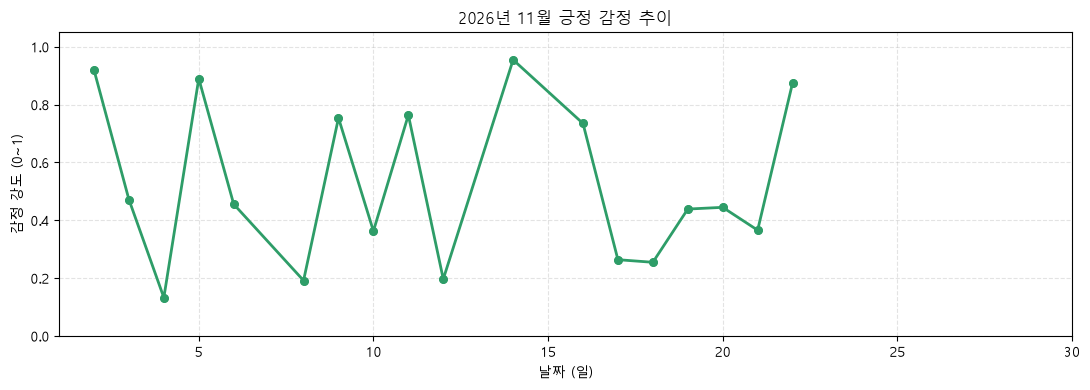

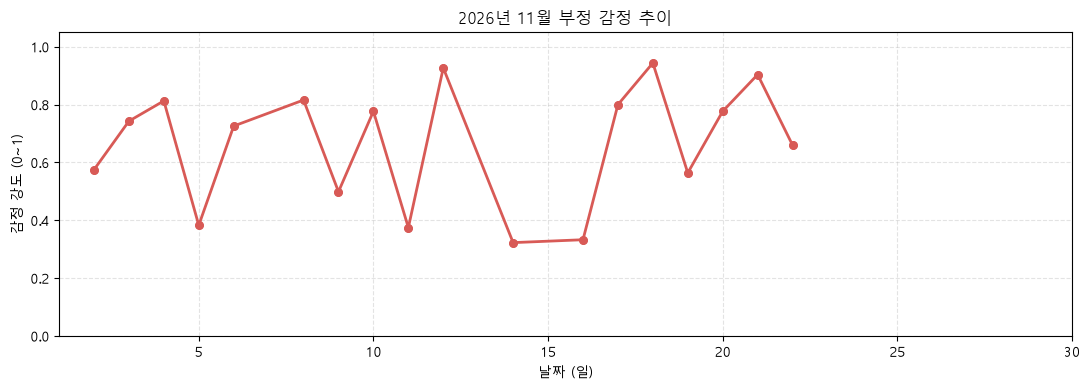

In [55]:
# 15. 한 달 감정 점수 그래프
def plot_month_score_graph(year, month, score_column, title, color, filename):
    month_data = get_month_data(year, month)
    fig, ax = plt.subplots(figsize=(11, 4))

    if not month_data.empty:
        days = np.array([day.day for day in month_data["date"]], dtype=int)
        scores = month_data[score_column].astype(float).to_numpy()
        ax.plot(days, scores, marker="o", markersize=5, linewidth=2, color=color)
        ax.scatter(days, scores, color=color, s=30, zorder=3)
    else:
        ax.text(0.5, 0.5, "해당 월에 작성된 일기가 없습니다.",
                ha="center", va="center", transform=ax.transAxes)

    ax.set_xlim(1, calendar.monthrange(year, month)[1])
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("날짜 (일)")
    ax.set_ylabel("감정 강도 (0~1)")
    ax.set_title(f"{year}년 {month}월 {title}")
    ax.grid(True, linestyle="--", alpha=0.35)
    fig.tight_layout()
    fig.savefig(output_dir / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def plot_positive_graph(year, month):
    plot_month_score_graph(
        year, month, "positive_score", "긍정 감정 추이", "#2E9D68",
        f"graph_positive_context_{year}_{month:02d}.png"
    )


def plot_negative_graph(year, month):
    plot_month_score_graph(
        year, month, "negative_score", "부정 감정 추이", "#D85A56",
        f"graph_negative_context_{year}_{month:02d}.png"
    )


plot_positive_graph(SELECT_YEAR, SELECT_MONTH)
plot_negative_graph(SELECT_YEAR, SELECT_MONTH)


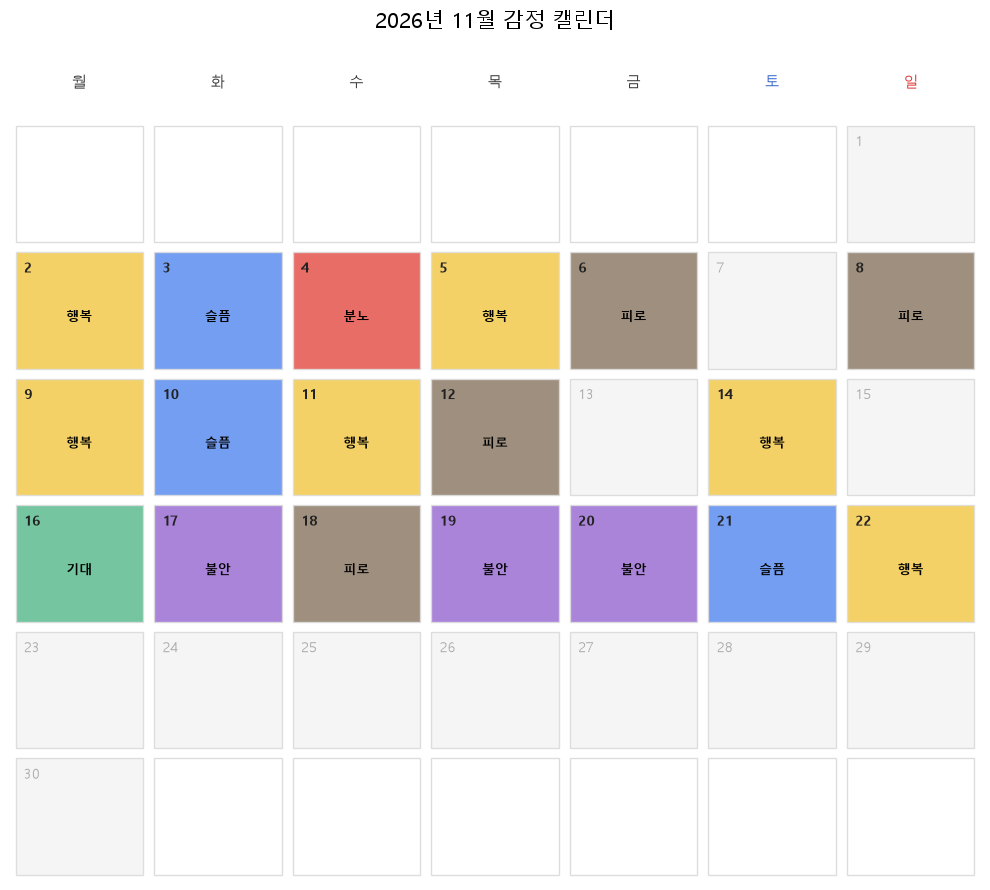

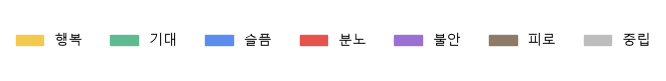

In [56]:
# 16. 한 달 전체 감정 캘린더 — 혼합 색상 없음
def plot_emotion_calendar(year, month):
    draw_month_calendar(
        year=year,
        month=month,
        value_column="valence",
        emotion_column="main_emotion",
        title="감정 캘린더",
        filename=f"calendar_emotion_context_{year}_{month:02d}.png",
        mode="emotion"
    )

    handles = [Patch(color=EMOTION_COLORS[emotion], label=emotion)
               for emotion in DISPLAY_EMOTIONS]
    fig, ax = plt.subplots(figsize=(8, 0.8))
    ax.axis("off")
    ax.legend(handles=handles, loc="center", ncol=7, frameon=False)
    plt.show()


plot_emotion_calendar(SELECT_YEAR, SELECT_MONTH)


In [57]:
# 17. 지정한 달의 그래프 2개 + 전체 감정 캘린더
def show_month_summary(year, month):
    print(f"{year}년 {month}월")
    print("1) 긍정 감정 그래프")
    plot_positive_graph(year, month)
    print("2) 부정 감정 그래프")
    plot_negative_graph(year, month)
    print("3) 전체 감정 캘린더")
    plot_emotion_calendar(year, month)


In [58]:
# 18. 오늘 일기 쓰기 + 분석 결과 자동 갱신
def write_diary(text, day=None, save=True, refresh=True):
    global diary, daily, sentences

    day = day or date.today()
    result, sentence_rows, _ = analyze_text(text)

    print(f"[{day}]")
    print("(* = 문맥 검증을 통과한 직접 감정 표현)")

    for row in sentence_rows:
        print(f"- {row['sentence']}")
        print(
            f"  → 대표: {row['main_emotion']} {row['representative_score']:.3f} | "
            f"2순위: {row['runner_up_emotion']} {row['runner_up_score']:.3f} | "
            f"차이: {row['representative_gap']:.3f} ({row['dominance_level']})"
        )
        print(
            f"  → P {row['positive_score']:.3f} / N {row['negative_score']:.3f} / "
            f"차이 {row['polarity_gap']:.3f} / 중립 {row['neutral_score']:.3f}"
        )
        if row["context_changed_representative"]:
            print(f"  → 문맥 보정 전 대표: {row['raw_main_emotion']}")
        print(f"  → 세부: {row['emotions']}")
        if row["direct_emotions"] != "없음":
            print(f"  → 직접 감정 인정: {row['direct_emotions']}")
        if row["excluded_mentions"] != "없음":
            print(f"  → 문맥상 제외: {row['excluded_mentions']}")
        if row["context_adjusted_labels"] != "없음":
            print(f"  → 최종 점수에서 보정: {row['context_adjusted_labels']}")

    print("\nPositive:", result["positive_score"], "|", result["positive_emotion"])
    print("Negative:", result["negative_score"], "|", result["negative_emotion"])
    print("Positive-Negative 차이:", result["polarity_gap"])
    print("Neutral (없음):", result["neutral_score"])
    print("대표 감정:", result["main_emotion"], "| 강도:", result["representative_score"])
    print(
        "2순위 감정:", result["runner_up_emotion"],
        "| 강도:", result["runner_up_score"],
        "| 대표 격차:", result["representative_gap"],
        "| 우세도:", result["dominance_level"]
    )
    if result["context_changed_representative"]:
        print("문맥 보정 전 대표 감정:", result["raw_main_emotion"])
    print("Valence:", result["valence"])
    print("직접 감정 인정:", result["direct_emotions"])
    print("문맥상 제외:", result["excluded_mentions"])
    print("최종 점수에서 보정:", result["context_adjusted_labels"])
    print("세부 Top5:", result["top_emotions"])

    temporary = {**result}
    temporary["comment"] = daily_comment(temporary)
    print("코멘트:", temporary["comment"])

    if not save:
        return temporary

    old = pd.read_csv(DIARY_FILE, encoding="utf-8-sig")
    old = old[old["date"] != str(day)]
    new_row = pd.DataFrame([{"date": str(day), "text": text}])
    old = pd.concat([old, new_row], ignore_index=True).sort_values("date")
    old.to_csv(DIARY_FILE, index=False, encoding="utf-8-sig")
    print("\n일기 저장 완료")

    if refresh:
        diary = pd.read_csv(DIARY_FILE, encoding="utf-8-sig")
        diary["date"] = pd.to_datetime(diary["date"]).dt.date
        diary = diary.sort_values("date").reset_index(drop=True)
        daily, sentences = build_daily_outputs()
        print("분석 결과 자동 갱신 완료")
        show_month_summary(day.year, day.month)

    return temporary


In [59]:
# 19. 최종 테스트 — 대표 감정 하나 + 문맥 보정 + 우세도
result = write_diary(
    "오늘 시험을 잘 봐서 뿌듯했지만 다른 발표가 걱정되고 너무 피곤하다.",
    save=False
)


[2026-11-23]
(* = 문맥 검증을 통과한 직접 감정 표현)
- 오늘 시험을 잘 봐서 뿌듯했다
  → 대표: 행복 0.979 | 2순위: 기대 0.279 | 차이: 0.700 (높음)
  → P 0.979 / N 0.192 / 차이 0.787 / 중립 0.111
  → 세부: *뿌듯함 0.84, 기쁨 0.98, 행복 0.98, 고마움 0.96, 즐거움/신남 0.94
  → 직접 감정 인정: 뿌듯함
- 다른 발표가 걱정되고 너무 피곤하다.
  → 대표: 피로 0.816 | 2순위: 불안 0.630 | 차이: 0.186 (높음)
  → P 0.248 / N 0.816 / 차이 0.568 / 중립 0.212
  → 세부: *힘듦/지침 0.91, *불안/걱정 0.73, 지긋지긋 0.72, 짜증 0.70, 귀찮음 0.64
  → 직접 감정 인정: 힘듦/지침, 불안/걱정

Positive: 0.578 | 행복
Negative: 0.504 | 피로
Positive-Negative 차이: 0.074
Neutral (없음): 0.161
대표 감정: 행복 | 강도: 0.578
2순위 감정: 피로 | 강도: 0.504 | 대표 격차: 0.074 | 우세도: 낮음
Valence: 0.074
직접 감정 인정: 힘듦/지침, 뿌듯함, 불안/걱정
문맥상 제외: 없음
최종 점수에서 보정: 없음
세부 Top5: 힘듦/지침, 뿌듯함, 불안/걱정, 기쁨, 행복
코멘트: 긍정적인 감정이 더 강하게 나타난 하루예요. 좋았던 순간을 기억해두세요. 다만 2순위 감정인 피로과의 차이가 0.074로 작습니다. 직접 표현된 감정: 힘듦/지침, 뿌듯함, 불안/걱정.


In [60]:
# 20. 긴 일기 테스트 — 파일이 있을 때만 실행
long_diary_path = data_dir / "test_diary_long.txt"
if long_diary_path.exists():
    long_text = long_diary_path.read_text(encoding="utf-8")
    result = write_diary(long_text, save=False)
else:
    print("긴 일기 테스트 생략: 파일이 없습니다 →", long_diary_path)


[2026-11-23]
(* = 문맥 검증을 통과한 직접 감정 표현)
- 아침에 알람을 못 듣고 늦잠을 자서 1교시에 지각했다.
  → 대표: 피로 0.909 | 2순위: 분노 0.815 | 차이: 0.094 (보통)
  → P 0.358 / N 0.909 / 차이 0.551 / 중립 0.408
  → 세부: 힘듦/지침 0.95, 당황/난처 0.92, 짜증 0.89, 지긋지긋 0.87, 귀찮음 0.82
- 교수님이 출석을 다 부른 뒤에 들어가서 너무 민망했다.
  → 대표: 분노 0.893 | 2순위: 불안 0.842 | 차이: 0.050 (낮음)
  → P 0.083 / N 0.893 / 차이 0.810 / 중립 0.058
  → 세부: *부끄러움 0.71, 당황/난처 0.91, 짜증 0.91, 불평/불만 0.88, 화남/분노 0.86
  → 직접 감정 인정: 부끄러움
- 그래도 수업 내용은 생각보다 재미있어서 금방 집중할 수 있었다.
  → 대표: 행복 0.956 | 2순위: 기대 0.600 | 차이: 0.355 (높음)
  → P 0.956 / N 0.286 / 차이 0.669 / 중립 0.161
  → 세부: *즐거움/신남 0.94, 기쁨 0.97, 행복 0.93, 편안/쾌적 0.92, 안심/신뢰 0.90
  → 직접 감정 인정: 즐거움/신남
- 점심에는 친구가 밥을 사 줘서 정말 고마웠다.
  → 대표: 행복 0.967 | 2순위: 기대 0.162 | 차이: 0.806 (높음)
  → P 0.967 / N 0.117 / 차이 0.850 / 중립 0.109
  → 세부: *고마움 0.98, 기쁨 0.96, 행복 0.95, 감동/감탄 0.83, 즐거움/신남 0.75
  → 직접 감정 인정: 고마움
- 오후에는 팀 프로젝트 회의를 했는데 내가 맡은 부분에서 오류가 계속 나서 답답했다.
  → 대표: 분노 0.824 | 2순위: 피로 0.791 | 차이: 0.033 (낮음)
  → P 0.206 / N 0.824 / 차이 0.618 / 중립 0.227
  →

In [61]:
# 21. 최종 출력 기준 회귀 테스트
# 인정된 직접 감정은 Top5에 포함되고, 문맥상 제외된 정확한 라벨은 Top5에서 제거되는지 확인한다.
OUTPUT_REGRESSION_CASES = [
    ("교수님이 출석을 다 부른 뒤에 들어가서 너무 민망했다.", {"부끄러움"}, set()),
    ("친구가 밥을 사 줘서 정말 고마웠다.", {"고마움"}, set()),
    ("실수로 주문을 잘못 받아서 손님에게 미안했다.", {"죄책감"}, set()),
    ("합격하면 행복할 것 같다.", set(), {"행복"}),
    ("행복했으면 좋겠다.", set(), {"행복"}),
    ("절망할 것 같았다.", set(), {"절망"}),
    ("친구가 행복해 보였다.", set(), {"행복"}),
    ("오늘은 생각보다 하나도 안 지루한 하루였다.", set(), {"재미없음"}),
]

regression_rows = []
for sentence, must_include, must_exclude in OUTPUT_REGRESSION_CASES:
    day_result, _, _ = analyze_text(sentence)
    top_set = {
        value.strip()
        for value in day_result["top_emotions"].split(",")
        if value.strip()
    }
    include_ok = must_include <= top_set
    exclude_ok = top_set.isdisjoint(must_exclude)
    regression_rows.append({
        "문장": sentence,
        "Top5": day_result["top_emotions"],
        "반드시 포함": ", ".join(sorted(must_include)) or "없음",
        "반드시 제외": ", ".join(sorted(must_exclude)) or "없음",
        "포함 통과": include_ok,
        "제외 통과": exclude_ok,
        "대표(보정 전→후)": f"{day_result['raw_main_emotion']} → {day_result['main_emotion']}"
    })

output_regression = pd.DataFrame(regression_rows)
display(output_regression)
assert output_regression[["포함 통과", "제외 통과"]].all().all(), "최종 출력 회귀 테스트 실패"
print(f"최종 출력 회귀 테스트 {len(output_regression)}건 전체 통과")


,문장,Top5,반드시 포함,반드시 제외,포함 통과,제외 통과,대표(보정 전→후)
0,교수님이 출석을 다 부른 뒤에 들어가서 너무 민망했다.,"부끄러움, 당황/난처, 짜증, 불평/불만, 화남/분노",부끄러움,없음,True,True,분노 → 분노
1,친구가 밥을 사 줘서 정말 고마웠다.,"고마움, 기쁨, 행복, 감동/감탄, 안심/신뢰",고마움,없음,True,True,행복 → 행복
2,실수로 주문을 잘못 받아서 손님에게 미안했다.,"죄책감, 당황/난처, 안타까움/실망, 부끄러움, 슬픔",죄책감,없음,True,True,슬픔 → 슬픔
3,합격하면 행복할 것 같다.,"기대감, 환영/호의, 아껴주는, 안심/신뢰, 신기함/관심",없음,행복,True,True,행복 → 행복
4,행복했으면 좋겠다.,"아껴주는, 기대감, 슬픔, 힘듦/지침, 불쌍함/연민",없음,행복,True,True,슬픔 → 슬픔
5,절망할 것 같았다.,"슬픔, 힘듦/지침, 불안/걱정, 패배/자기혐오, 서러움",없음,절망,True,True,슬픔 → 슬픔
6,친구가 행복해 보였다.,"기쁨, 아껴주는, 고마움, 안심/신뢰, 편안/쾌적",없음,행복,True,True,행복 → 행복
7,오늘은 생각보다 하나도 안 지루한 하루였다.,"힘듦/지침, 지긋지긋, 짜증, 불평/불만, 귀찮음",없음,재미없음,True,True,피로 → 피로


최종 출력 회귀 테스트 8건 전체 통과


---
# 사용자 화면

위 셀들은 개발·검증용 출력(P/N 점수, 우세도 수치, 문맥 보정 전/후 등)입니다.  
아래 셀은 **실제 사용자가 보는 화면**만 따로 만든 것으로, 분석 로직은 위와 완전히 같습니다(`analyze_text` 결과를 보기 좋게 표시만 함).

| 함수 | 보여주는 것 |
|---|---|
| `show_day(text, day=None, save=False, save_html=False, name=None)` | 하루 결과 카드: 대표 감정, 긍정·부정 막대, 세부 감정 Top5, 한 줄 코멘트 |
| `show_month(year, month)` | 한 달 요약 카드: 대표 감정 분포, 자주 나온 세부 감정, 가장 좋았던 날·힘들었던 날 + 감정 캘린더·그래프 |

In [62]:
# 22. 사용자 화면 — 공통 스타일·도우미
import html as _html
from collections import Counter
from IPython.display import HTML

WEEKDAYS = "월화수목금토일"
CARD_CSS = """
<style>
.dcard{font-family:'Malgun Gothic','Apple SD Gothic Neo','Noto Sans KR',sans-serif;max-width:620px;
       background:#fff;color:#222;border:1px solid #e3e3e3;border-radius:14px;padding:20px 22px;margin:10px 0;
       box-shadow:0 2px 8px rgba(0,0,0,.06);line-height:1.5}
.dcard h3{margin:0 0 2px 0;font-size:15px;color:#666;font-weight:600}
.dcard .main{display:flex;align-items:center;gap:12px;margin:8px 0 4px}
.dcard .chip-main{font-size:22px;font-weight:700;padding:4px 16px;border-radius:999px;color:#222}
.dcard .sub{font-size:13px;color:#666}
.dcard .sec{margin-top:16px;font-size:13px;font-weight:700;color:#444}
.dcard .barrow{display:flex;align-items:center;gap:8px;font-size:13px;margin:5px 0}
.dcard .barrow .name{width:34px;color:#555}
.dcard .bar{flex:1;height:10px;background:#f0f0f0;border-radius:6px;overflow:hidden}
.dcard .bar>div{height:100%;border-radius:6px}
.dcard .barrow .pct{width:38px;text-align:right;color:#555}
.dcard .chips{display:flex;flex-wrap:wrap;gap:6px;margin-top:6px}
.dcard .chip{font-size:13px;padding:3px 10px;border-radius:999px;border:1px solid transparent}
.dcard .chip.direct{border-color:#333;font-weight:700}
.dcard .comment{margin-top:16px;background:#f7f7f9;border-radius:10px;padding:10px 12px;font-size:14px}
.dcard details{margin-top:14px;font-size:13px}
.dcard summary{cursor:pointer;color:#555;font-weight:600}
.dcard .sent{margin:8px 0 0 2px;padding-left:10px;border-left:3px solid #ddd}
.dcard .sent .emo{color:#555;font-size:12px}
.dcard .note{margin-top:12px;font-size:11px;color:#999}
.dcard .two{display:flex;gap:10px;margin-top:6px}
.dcard .box{flex:1;background:#f7f7f9;border-radius:10px;padding:8px 10px;font-size:13px}
</style>
"""

def _esc(text):
    return _html.escape(str(text))

def _soft(color, alpha="33"):
    """#RRGGBB → 연한 배경색(#RRGGBBAA)"""
    return f"{color}{alpha}"

def _label_color(label):
    """세부 감정 → 그 감정이 속한 대표 감정 색"""
    if label not in LABELS:
        return "#BDBDBD"
    return EMOTION_COLORS[DISPLAY_EMOTION[LABEL_GROUP[LABELS.index(label)]]]

def _split_names(value):
    """'*부끄러움 0.71, 당황/난처 0.91' → [('부끄러움', True), ('당황/난처', False)]"""
    if not value or value == "없음":
        return []
    names = []
    for part in str(value).split(","):
        part = part.strip()
        if not part:
            continue
        direct = part.startswith("*")
        name = part.lstrip("*").rsplit(" ", 1)[0] if " " in part else part.lstrip("*")
        names.append((name, direct))
    return names

def dominance_text(row):
    level = row.get("dominance_level")
    if level == "중립 판정":
        return "뚜렷한 감정이 적은 잔잔한 하루예요"
    if level == "높음":
        return "이 감정이 뚜렷하게 나타났어요"
    if level == "보통":
        return "이 감정이 비교적 뚜렷해요"
    return f"'{row.get('runner_up_emotion', '다른 감정')}' 감정도 비슷하게 나타났어요"

def user_comment(row):
    """사용자용 코멘트: 수치 없이 한두 문장"""
    base = {
        "행복": "좋은 순간이 많았던 하루예요. 그 기분을 기억해 두세요.",
        "기대": "앞으로의 일을 기대하는 마음이 보이는 하루예요.",
        "피로": "많이 지친 하루였어요. 오늘은 푹 쉬어요.",
        "불안": "걱정이 많았던 하루예요. 너무 혼자 끌어안지 마세요.",
        "분노": "속상하거나 답답한 일이 있었네요.",
        "슬픔": "마음이 무거운 하루였어요. 내일은 조금 더 가벼워지길 바라요.",
        "중립": "잔잔하게 지나간 하루였어요."
    }.get(row["main_emotion"], "여러 감정이 함께한 하루였어요.")
    pos, neg = row["positive_score"], row["negative_score"]
    if row["main_emotion"] not in {"행복", "기대", "중립"} and pos >= 0.5:
        base += " 그래도 좋은 감정도 분명히 있었어요."
    elif row["main_emotion"] in {"행복", "기대"} and neg >= 0.5:
        base += " 힘든 순간도 있었지만 잘 지나왔어요."
    return base

def _bar(name, score, color):
    pct = int(round(max(0.0, min(1.0, float(score))) * 100))
    return (f'<div class="barrow"><span class="name">{name}</span>'
            f'<div class="bar"><div style="width:{pct}%;background:{color}"></div></div>'
            f'<span class="pct">{pct}%</span></div>')

In [63]:
# 23. 사용자 화면 — 하루 결과 카드
def render_day_card(result, sentence_rows, day=None):
    day = day or date.today()
    if isinstance(day, str):
        day = pd.to_datetime(day).date()
    main = result["main_emotion"]
    color = EMOTION_COLORS[main]

    tops = [x.strip() for x in str(result["top_emotions"]).split(",") if x.strip()][:5]
    chips = "".join(
        f'<span class="chip" style="background:{_soft(_label_color(t))}">{_esc(t)}</span>'
        for t in tops
    ) or '<span class="sub">없음</span>'

    return CARD_CSS + f"""
<div class="dcard">
  <h3>{day.year}년 {day.month}월 {day.day}일 ({WEEKDAYS[day.weekday()]}) 일기</h3>
  <div class="main">
    <span class="chip-main" style="background:{_soft(color, '66')}">{_esc(main)}</span>
    <span class="sub">{_esc(dominance_text(result))}</span>
  </div>

  <div class="sec">긍정 · 부정</div>
  {_bar("긍정", result["positive_score"], "#4CAF7A")}
  {_bar("부정", result["negative_score"], "#E06C66")}

  <div class="sec">오늘 나타난 감정</div>
  <div class="chips">{chips}</div>

  <div class="comment">💬 {_esc(user_comment(result))}</div>
</div>"""


def _save_diary_quiet(text, day):
    """일기를 파일에 저장하고 분석 결과를 다시 만든다 (출력 없이)"""
    global diary, daily, sentences
    old = pd.read_csv(DIARY_FILE, encoding="utf-8-sig")
    old = old[old["date"] != str(day)]
    old = pd.concat([old, pd.DataFrame([{"date": str(day), "text": text}])], ignore_index=True).sort_values("date")
    old.to_csv(DIARY_FILE, index=False, encoding="utf-8-sig")
    diary = pd.read_csv(DIARY_FILE, encoding="utf-8-sig")
    diary["date"] = pd.to_datetime(diary["date"]).dt.date
    diary = diary.sort_values("date").reset_index(drop=True)
    daily, sentences = build_daily_outputs()


def show_day(text, day=None, save=False, save_html=False, name=None):
    """일기 한 편 → 사용자용 결과 카드. save=True면 일기 파일에도 저장, save_html=True면 outputs/에 html 저장"""
    day = day or date.today()
    if isinstance(day, str):
        day = pd.to_datetime(day).date()
    result, sentence_rows, _ = analyze_text(text)
    card = render_day_card(result, sentence_rows, day)
    display(HTML(card))
    if save:
        _save_diary_quiet(text, day)
        print(f"{day} 일기 저장 완료 → 캘린더·그래프에 반영됨")
    if save_html:
        path = output_dir / f"card_day_{name or day}.html"
        path.write_text("<meta charset='utf-8'>" + card, encoding="utf-8")
        print("카드 저장:", path)
    return result

In [64]:
# 24. 사용자 화면 — 한 달 요약 카드
def render_month_card(year, month):
    md = get_month_data(year, month)
    if md.empty:
        return CARD_CSS + f'<div class="dcard"><h3>{year}년 {month}월</h3>작성한 일기가 없어요.</div>'

    counts = md["main_emotion"].value_counts()
    total = len(md)
    dist = "".join(
        _bar(_esc(e), counts.get(e, 0) / total, EMOTION_COLORS[e]).replace(
            f'{int(round(counts.get(e, 0) / total * 100))}%</span>', f'{int(counts.get(e, 0))}일</span>')
        for e in DISPLAY_EMOTIONS if counts.get(e, 0) > 0
    )

    detail = Counter(
        t.strip() for v in md["top_emotions"] for t in str(v).split(",")[:3] if t.strip()
    ).most_common(5)
    chips = "".join(
        f'<span class="chip" style="background:{_soft(_label_color(n))}">{_esc(n)} {c}회</span>'
        for n, c in detail
    )

    best = md.loc[md["valence"].idxmax()]
    worst = md.loc[md["valence"].idxmin()]
    def short(row):
        d = row["date"]
        first = str(row["text"]).split(".")[0][:28]
        return f'<b>{d.month}/{d.day} ({WEEKDAYS[d.weekday()]})</b> · {_esc(row["main_emotion"])}<br><span class="sub">{_esc(first)}…</span>'

    top_emotion = counts.index[0]
    return CARD_CSS + f"""
<div class="dcard">
  <h3>{year}년 {month}월 감정 요약 · 일기 {total}일</h3>
  <div class="main">
    <span class="chip-main" style="background:{_soft(EMOTION_COLORS[top_emotion], '66')}">{_esc(top_emotion)}</span>
    <span class="sub">이번 달 가장 많았던 대표 감정 ({int(counts.iloc[0])}일)</span>
  </div>
  <div class="sec">대표 감정 분포</div>
  {dist}
  <div class="sec">자주 나온 세부 감정</div>
  <div class="chips">{chips}</div>
  <div class="two">
    <div class="box">😊 가장 좋았던 날<br>{short(best)}</div>
    <div class="box">🌧 가장 힘들었던 날<br>{short(worst)}</div>
  </div>
</div>"""


def show_month(year=None, month=None, with_graphs=True, save_html=False):
    year = year or SELECT_YEAR
    month = month or SELECT_MONTH
    card = render_month_card(year, month)
    display(HTML(card))
    if save_html:
        path = output_dir / f"card_month_{year}_{month:02d}.html"
        path.write_text("<meta charset='utf-8'>" + card, encoding="utf-8")
        print("카드 저장:", path)
    if with_graphs:
        plot_emotion_calendar(year, month)
        plot_positive_graph(year, month)
        plot_negative_graph(year, month)

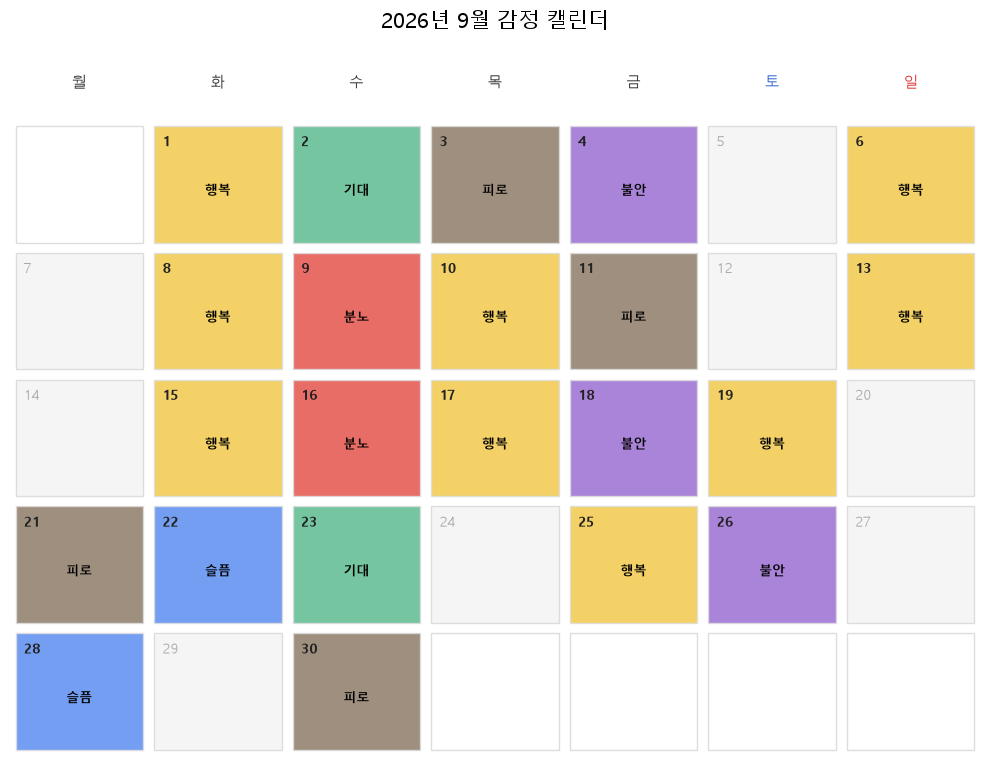

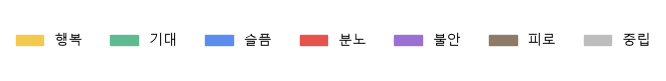

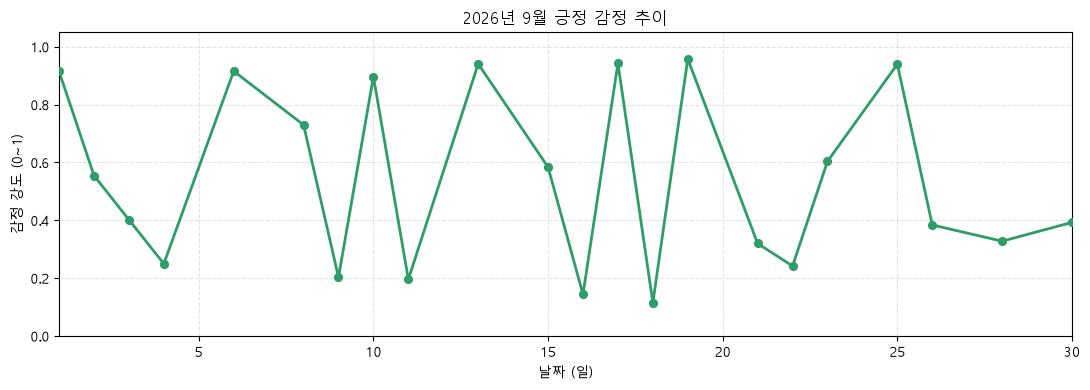

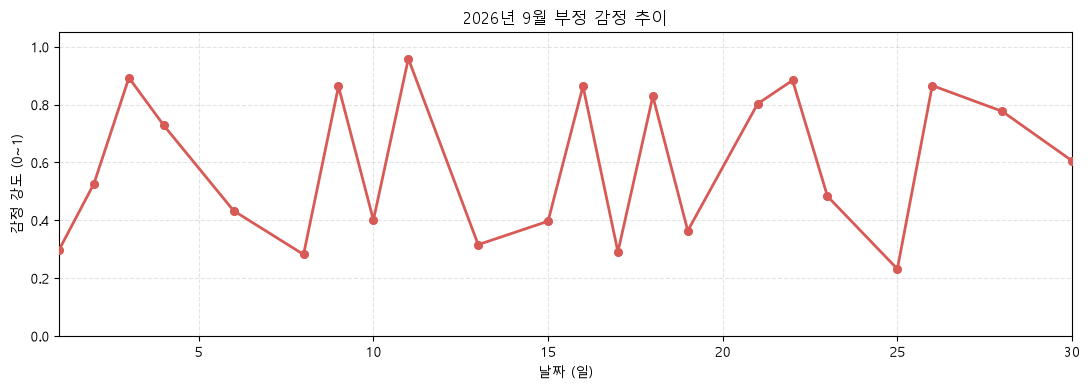

In [67]:
# 25. 사용자 화면 데모 (발표 시연용)
# 오늘 일기 하나 → 결과 카드  (save=True 로 바꾸면 일기 파일에 저장되고 캘린더에도 반영)
_ = show_day("오늘 드디어 과제를 다 끝내서 너무 홀가분하고 뿌듯하다.", save=False, save_html=False, name="example")

# 긴 일기
long_path = data_dir / "test_diary_long2.txt"
if long_path.exists():
    _ = show_day(long_path.read_text(encoding="utf-8"), save=False, save_html=False, name="long")

# 한 달 요약
show_month(2026, 9, save_html=False)